# NLeEDM magnetic field simulation
We want **1.23 G along Z**, with Bz between **0.98 and 1.48 G** throughout both laser windows.

We use exactly **4 supplies**:
- Supply 1: the window coils in series in X-direction.
- Supply 2: the window coils in series in Y-direction.
- Supply 3: the outer circular Z coils in series.
- Supply 4: the middle circular Z coils.

We compare winding widths and turn counts, fit the two currents, and report field quality and heating. Current is assumed unrestricted for this study.

## 1. Importing the libraries
We are using the Magpylib to calculate the magnetic field and SciPy to find the currents. The other libraries help to work with arrays, show tables, and make plots.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy
from scipy.optimize import minimize, linprog
from IPython.display import display, Markdown

## 2. Inputs
Keep physical dimensions and assumptions here. The **1.05 mm winding pitch** includes winding imperfections around the holder; the assumed **1.00 mm bare copper diameter** determines resistance.

### Target and ambient field

In [2]:
# Field goal. All magnetic field inputs are in Gauss (G).
target_field_G = 1.23
target_vector_G = np.array([0.0, 0.0, target_field_G]) # Desired field vector
allowed_error_G = 0.25
ambient_field_G = np.array([-0.1458, -0.4365, -0.2409])

### Chamber and coil Dimensions
There are **two window positions** along Z. At each position there are four window coils: two with their flat side facing X and two facing Y. This gives **eight window coils in total**. The three Z coils are separate circular coils.

| Part | Position or size |
|---|---|
| Chamber | Z = 0 to 600 mm |
| Window centres | Z = 158.4 and 441.6 mm |
| Window wire loop | 77 × 198 mm, before windings |
| Z-coil centres | Z = −25, 300 and 625 mm |
| Z-coil starting radius | 130 mm |
| Beam region | 160 mm per window |

The same coordinate convention is used as from Waleed's Thesis.

In [ ]:
# Chamber geometry. All lengths below are in metres.
chamber_length_m = 0.600 # Total length

# Window geometry
window_regions_m = [(0.0784, 0.2384), (0.3616, 0.5216)]

# Circular Z coils.
z_coil_radius_m = 0.130
z_coil_positions_m = [-0.025, 0.300, 0.625]
z_winding_width_m = 0.036

# Window dimensions
window_loop_height_m = 0.077
window_loop_length_m = 0.198
windows_gap_x_m = 0.206 # The gap between windows oposing eachother. 

### Beam inputs

In [4]:
# Beam region
beam_radius_m = 0.008 # Eval radius
beam_fwhm_m = 0.006
search_grid_xy = 5
search_grid_z = 21

### Wire inputs

In [5]:
# Geometry
wire_diameter_m = 0.00105

### Optimal turns inputs

In [6]:
# Fixed turns for every circular Z coils
z_coil_turns = 92

# Turns per window coil to evaluate.
window_turn_choices = [80, 90, 100, 110, 120]

window_width_choices_m = [0.013, 0.014, 0.015, 0.016, 0.017, 0.018, 0.020, 0.026, 0.032, 0.036]


## 3. The coils

### Placing the individual turns
Let us build each coil from separate turns. The simple model just puts the turns next to each other until a layer is full, then start the next layer. 

The function below returns the positions for each turn.

In [7]:
def get_turn_positions(number_of_turns, winding_width_m):
    """Return the width position and layer position of each turn."""
    turns_per_layer = int(np.floor(winding_width_m / wire_diameter_m + 1e-9))
    positions = []
    turns_left = number_of_turns
    layer = 0

    while turns_left > 0:
        turns_in_layer = min(turns_per_layer, turns_left)
        layer_position_m = (layer + 0.5) * wire_diameter_m

        for turn in range(turns_in_layer):
            width_position_m = (turn - (turns_in_layer - 1) / 2) * wire_diameter_m
            positions.append((width_position_m, layer_position_m))

        turns_left -= turns_in_layer
        layer += 1

    return positions

### Making a rectangular window coil
We make one rectangular loop from its four corners. Each extra layer makes the rectangle slightly larger. Moving across the winding width moves the loop away from the chamber.

In [8]:
def create_window_coil(name, axis, centre_m, turns, winding_width_m):
    """Build one window coil at 1 A."""
    loops = []
    wire_length_m = 0.0

    for width, depth in get_turn_positions(turns, winding_width_m):
        half_x = window_loop_height_m / 2 + depth
        half_z = window_loop_length_m / 2 + depth
        wire_length_m += 4 * (half_x + half_z)

        vertices = np.array([
            [-half_x, width, -half_z],
            [ half_x, width, -half_z],
            [ half_x, width,  half_z],
            [-half_x, width,  half_z],
            [-half_x, width, -half_z],
        ])

        if axis == "X":
            vertices = vertices[:, [1, 0, 2]]

        vertices += np.asarray(centre_m)
        loops.append(
            magpy.current.Polyline(current=1.0, vertices=vertices)
        )

    return {
        "name": name,
        "group": axis,
        "turns": turns,
        "wire_length_m": wire_length_m,
        "source": magpy.Collection(*loops),
    }


### Making a circular Z coil
We use circular turns, positive current gives a field along +Z. We then also add up the circumference of every turn to find the wire length.

In [9]:
def create_z_coil(name, centre_z_m, turns):
    """Build one circular Z coil at 1 A and add up its wire length."""
    turn_positions = get_turn_positions(turns, z_winding_width_m)
    loops = []
    wire_length_m = 0.0
    
    for width_position_m, layer_position_m in turn_positions:
        radius_m = z_coil_radius_m + layer_position_m
        position = (0.0, 0.0, centre_z_m + width_position_m)
        loop = magpy.current.Circle(current=1.0, diameter=2 * radius_m, position=position)
        loops.append(loop)
        wire_length_m += 2 * np.pi * radius_m

    group = "Z middle" if name == "Z middle" else "Z outer"
    return {
        "name": name,
        "group": group,
        "turns": turns,
        "wire_length_m": wire_length_m,
        "source": magpy.Collection(*loops),
    }

### Putting all coils together
The gap is the separation between inward-facing winding surfaces. Increasing winding width moves the winding centres outward while keeping this gap fixed.

In [10]:
def create_all_coils(window_turns, window_width_m):
    """Create eight window coils and three Z coils."""
    distance = (windows_gap_x_m + window_width_m) / 2
    coils = []

    for axis in ["X", "Y"]:
        for number, region in enumerate(window_regions_m, start=1):
            for side, label in [(-1, "−"), (1, "+")]:
                centre = [0.0, 0.0, float(np.mean(region))]
                centre[0 if axis == "X" else 1] = side * distance

                coils.append(create_window_coil(
                    name=f"{axis}{number}{label}",
                    axis=axis,
                    centre_m=centre,
                    turns=window_turns,
                    winding_width_m=window_width_m,
                ))

    for name, z, count in zip(
        ["Z left", "Z middle", "Z right"],
        z_coil_positions_m,
        [z_coil_turns] * 3,
    ):
        coils.append(create_z_coil(name, z, count))

    return coils

# just a simple model for visualization / simulation, we still need to test different setups. 
reference_turns = 100
reference_window_width_m = 0.020
reference_coils = create_all_coils(reference_turns, reference_window_width_m)

### Looking at the coil layout
We use Magpylib's `Collection.show()` to draw the coils. This just helps to visualize the setup, and does not add any value to the simulation itself. It is a nice way to check if the coils have been implementend correctly. 

In [11]:
reference_collection = magpy.Collection()
coil_colours = {
    "X": "#1f77b4",
    "Y": "#ff7f0e",
    "Z outer": "#2ca02c",
    "Z middle": "#d62728",
}

for coil in reference_coils:
    displayed_coil = coil["source"].copy()
    displayed_coil.style.color = coil_colours[coil["group"]]
    reference_collection.add(displayed_coil)

reference_collection.show()

## 4. Making the evaluation grid
Sample a circular X/Y grid through each laser window. A Gaussian with **6 mm FWHM** gives more weight to the beam centre. Half weights at the Z endpoints implement trapezoidal integration over each window. Normalize the weights so they sum to one.

In [12]:
def create_beam_grid(points_xy=5, points_z=21):
    """Return points in the two beam cylinders and their averaging weights."""
    xy_values = np.linspace(-beam_radius_m, beam_radius_m, points_xy)
    beam_sigma_m = beam_fwhm_m / np.sqrt(8 * np.log(2))
    points = []
    weights = []

    for start_m, end_m in window_regions_m:
        z_values = np.linspace(start_m, end_m, points_z)
        for z_index, z_m in enumerate(z_values):
            end_weight = 0.5 if z_index in [0, points_z - 1] else 1.0
            for x_m in xy_values:
                for y_m in xy_values:
                    radius_squared = x_m**2 + y_m**2
                    if radius_squared <= beam_radius_m**2 * (1 + 1e-12):
                        beam_weight = np.exp(-radius_squared / (2 * beam_sigma_m**2))
                        points.append([x_m, y_m, z_m])
                        weights.append(beam_weight * end_weight)

    points = np.array(points)
    weights = np.array(weights)
    weights = weights / np.sum(weights)
    return points, weights

beam_points, beam_weights = create_beam_grid(search_grid_xy, search_grid_z)

### Looking at the weighted beam
The 3D view shows both window regions. The cross-section shows the first window at its centre: the beam has the most weight near X = Y = 0.

We use a finer transverse grid for this visualization only. The fitting grid is still controlled by the inputs given above.

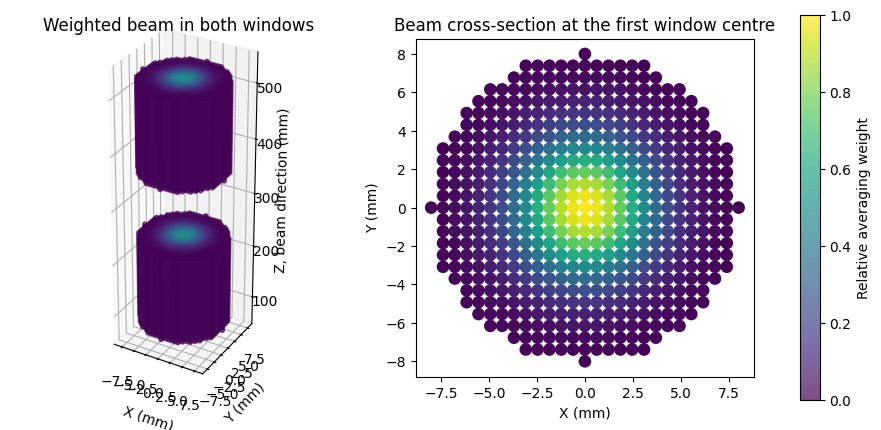

In [13]:
def plot_weighted_beam(points, weights):
    points_mm = points * 1000
    relative_weights = weights / np.max(weights)

    figure = plt.figure(figsize=(12, 5))
    beam_axis = figure.add_subplot(1, 2, 1, projection="3d")
    cross_section_axis = figure.add_subplot(1, 2, 2)

    colours = beam_axis.scatter(
        points_mm[:, 0], points_mm[:, 1], points_mm[:, 2],
        c=relative_weights, cmap="viridis", vmin=0, vmax=1,
        s=9, alpha=0.7)
    beam_axis.set_xlabel("X (mm)")
    beam_axis.set_ylabel("Y (mm)")
    beam_axis.set_zlabel("Z, beam direction (mm)")
    beam_axis.set_title("Weighted beam in both windows")
    beam_axis.set_box_aspect((1, 1, 3))

    first_window_centre_m = np.mean(window_regions_m[0])
    middle_slice = np.isclose(points[:, 2], first_window_centre_m)
    cross_section_axis.scatter(
        points_mm[middle_slice, 0], points_mm[middle_slice, 1],
        c=relative_weights[middle_slice], cmap="viridis", vmin=0, vmax=1, s=65,
    )
    cross_section_axis.set_xlabel("X (mm)")
    cross_section_axis.set_ylabel("Y (mm)")
    cross_section_axis.set_title("Beam cross-section at the first window centre")
    cross_section_axis.set_aspect("equal")
    figure.colorbar(colours, ax=[beam_axis, cross_section_axis], label="Relative averaging weight")
    plt.show()

visual_beam_points, visual_beam_weights = create_beam_grid(points_xy=27, points_z=31)
plot_weighted_beam(visual_beam_points, visual_beam_weights)

## 5. Calculating the field
Magpylib uses the Biot–Savart law for the straight wire segments and circular turns. To make this simple, we calculate each coil's field at **1 A** first.

The field is proportional to current. To find the total field we can multiply each coil's 1 A field by its current, add the coils together, and add the ambient field.

In [14]:
def calculate_fields_per_amp(coils, points):
    """Return each coil's field in G at 1 A."""
    fields_G = np.zeros((len(coils), len(points), 3))
    for coil_number, coil in enumerate(coils):
        for start in range(0, len(points), 512):
            stop = start + 512
            fields_G[coil_number, start:stop] = coil["source"].getB(points[start:stop]) * 1e4 # 1e4 is a T to G conversion
    return fields_G


def calculate_total_field(currents_A, fields_per_amp_G):
    """Multiply by current, add the coils, then add the ambient field."""
    coil_fields_G = currents_A[:, None, None] * fields_per_amp_G
    total_field_G = np.sum(coil_fields_G, axis=0)
    return total_field_G + ambient_field_G

### The field quality
There are several ways to quantify a "good field":

- **Mean Bz:** the average field along Z, using the beam weights.
- **Z RMS variation:** the typical spread of Bz around its own mean, as a percentage of 1.23 G.
- **Vector RMS error:** the typical distance from the full target `[0, 0, 1.23] G`, as a percentage of 1.23 G. This also counts unwanted X and Y fields.
- **Z peak-to-peak:** the largest Bz minus the smallest Bz.
- **Worst Z error:** the largest distance from 1.23 G at any sampled point.
- **Transverse field:** the unwanted field in X and Y, combined as `sqrt(Bx² + By²)`.

In [15]:
# Calculate all metrics that allows us to quantify how good the setup is.
def calculate_field_quality(field_G, weights):
    """Measure field quality relative to a target field along Z."""

    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()
    mean_field_G = np.sum(weights[:, None] * field_G, axis=0)

    target_vector_G = np.array([0.0, 0.0, target_field_G])
    vector_error_G = field_G - target_vector_G
    z_variation_G = field_G[:, 2] - mean_field_G[2]
    z_error_G = field_G[:, 2] - target_field_G
    transverse_squared = field_G[:, 0]**2 + field_G[:, 1]**2

    z_rms_G = np.sqrt(np.sum(weights * z_variation_G**2))
    vector_rms_G = np.sqrt(
        np.sum(weights * np.sum(vector_error_G**2, axis=1))
    )
    transverse_rms_G = np.sqrt(np.sum(weights * transverse_squared))
    target_magnitude_G = abs(target_field_G)

    return {
        "mean_z_G": mean_field_G[2],
        "bias_G": mean_field_G[2] - target_field_G,
        "z_rms_pct": 100 * z_rms_G / target_magnitude_G,
        "vector_rms_pct": 100 * vector_rms_G / target_magnitude_G,
        "z_ptp_G": np.ptp(field_G[:, 2]),
        "worst_z_G": np.max(np.abs(z_error_G)),
        "fraction_Z_in_band_pct": 100 * np.sum(
            weights * (np.abs(z_error_G) <= allowed_error_G)
        ),
        "transverse_rms_G": transverse_rms_G,
        "transverse_max_G": np.sqrt(np.max(transverse_squared)),
    }

In [16]:
# Helper function, nice to display
def show_table(rows):
    """Show a list of dictionaries as a table in the notebook."""
    headings = list(rows[0].keys())
    lines = ["| " + " | ".join(headings) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headings)) + " |")
    for row in rows:
        values = []
        for heading in headings:
            value = row[heading]
            if isinstance(value, (float, np.floating)):
                value = f"{value:.5g}"
            values.append(str(value))
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))

## 6. Reference: only the Z coils powered
This is a simple starting point. Leave all windows off and give the three Z coils the same current. Scale it until the weighted mean Bz is 1.23 G. The ambient X/Y field remains.

Reference geometry: 100 turns per window, 92 per Z coil, 20 mm winding width.

In [17]:
# Calculate field
reference_fields_G = calculate_fields_per_amp(reference_coils, beam_points)

# Mask only Z-components
z_mask = np.array([coil["group"].startswith("Z") for coil in reference_coils])
mean_z_per_amp_G = np.sum(beam_weights * reference_fields_G[z_mask, :, 2].sum(axis=0))
baseline_current_A = (target_field_G - ambient_field_G[2]) / mean_z_per_amp_G
baseline_currents_A = z_mask.astype(float) * baseline_current_A

# Scale current to get correct field
baseline_field_G = calculate_total_field(baseline_currents_A, reference_fields_G)

# Print results
print(f"Reference current: {baseline_current_A:.4f} A")
show_table([calculate_field_quality(baseline_field_G, beam_weights)])

Reference current: 0.5491 A


| mean_z_G | bias_G | z_rms_pct | vector_rms_pct | z_ptp_G | worst_z_G | fraction_Z_in_band_pct | transverse_rms_G | transverse_max_G |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1.23 | 4.4409e-16 | 18.811 | 41.894 | 0.83929 | 0.61762 | 82.5 | 0.46043 | 0.51388 |

## 7. Connecting exactly four supplies
Each column of the connection matrix is a supply. Each row is a coil: +1 means forward, −1 means reversed, and 0 means not on that supply.

- Supply 1: all X-direction window coils in series.
- Supply 2: all Y-direction window coils in series.
- Supply 3: the two outer circular Z coils in series.
- Supply 4: the middle circular Z coil.

Each group has an independent fitted current. Coils within a group share the same current and polarity. A negative fitted current means reverse that entire supply's connections and dial in the current magnitude. Only this fixed four-supply configuration is evaluated.


In [18]:
# Copper properties
copper_diameter_m = 0.00100  # Assumed bare copper diameter
copper_resistivity_20C = 1.72e-8  # ohm m
copper_temperature_coefficient = 0.00393  # per degree C
copper_area_m2 = np.pi * (copper_diameter_m / 2)**2
copper_area_mm2 = copper_area_m2 * 1e6
resistance_per_metre = copper_resistivity_20C / copper_area_m2

In [19]:
SUPPLY_GROUPS = ("X", "Y", "Z outer", "Z middle")
SUPPLY_LABELS = ("1: X windows", "2: Y windows", "3: Outer Z coils", "4: Middle Z coil")

# Connection matrix
def get_connections(coils):
    """Fixed series grouping, with one independent current per supply."""
    connections = np.zeros((len(coils), len(SUPPLY_GROUPS)))
    for row, coil in enumerate(coils):
        connections[row, SUPPLY_GROUPS.index(coil["group"])] = 1.0
    return connections

# adds the magnetic fields of all coils connected to matrix
def get_supply_fields(coil_fields_G, connections):
    return np.einsum("cs,cpd->spd", connections, coil_fields_G)

# Per coils, get length and multiply by resistance factor
def get_coil_resistances(coils):
    return np.array([
        coil["wire_length_m"] * resistance_per_metre
        for coil in coils
    ])

# Add eachs resistance to the matrix.
def get_supply_resistances(coils, connections):
    return np.abs(connections).T @ get_coil_resistances(coils)

## 8. Finding the four currents
For each layout with the fixed four-supply grouping:
1. Keep weighted mean Bz at 1.23 G.
2. Minimize the weighted full-vector error, including unwanted X/Y field.

Individual points may fall outside the reference Z band. The band is reported for information only; it does not constrain the currents or determine which design is selected.

We fit for field quality, then compare the electrical power of the fitted designs.


In [20]:
def fit_currents(supply_fields_G, weights):
    """Minimize weighted vector error with a fixed weighted mean Bz."""

    number_of_supplies = len(SUPPLY_GROUPS)
    mean_z = supply_fields_G[:, :, 2] @ weights # Calculate weighted average of field along Z
    required_z = target_field_G - ambient_field_G[2] # Remove ambient field

    # Finding initial condition.
    # Current aim is to find a correct current for correct average field.
    # Does not consider uniform field. 
    start = linprog(
        c=np.zeros(number_of_supplies),
        A_eq=mean_z[None, :], b_eq=[required_z],
        bounds=[(None, None)] * number_of_supplies, method="highs",
    )

    # If no proper initial condition can be found
    if not start.success:
        return None

    # Calculate the field error for any four currents
    matrix = supply_fields_G.transpose(1, 2, 0).reshape(-1, number_of_supplies)
    offset = np.tile(ambient_field_G - target_vector_G, len(weights))

    # Set weights
    w = np.repeat(weights, 3) / target_field_G**2

    # Weighted least squares method
    hessian = matrix.T @ (w[:, None] * matrix)
    linear = matrix.T @ (w * offset)
    constant = np.sum(w * offset**2)

    # Evaluate error
    def field_cost(currents):
        return currents @ hessian @ currents + 2 * linear @ currents + constant

    def field_gradient(currents):
        return 2 * (hessian @ currents + linear)

    # Constraints for the optimizer
    constraints = [{"type": "eq", "fun": lambda x: mean_z @ x - required_z,
                    "jac": lambda x: mean_z}]
    
    # Optimize!
    result = minimize(field_cost, start.x, jac=field_gradient, method="SLSQP",
                      constraints=constraints,
                      options={"ftol": 1e-11, "maxiter": 300})

    # In case when no optimal solution is found.
    if not result.success or abs(mean_z @ result.x - required_z) > 1e-7:
        return None
    
    return result.x


def fit_layout(coils, coil_fields_G, weights):
    """Fit the fixed four-supply grouping for this geometry."""

    connections = get_connections(coils)
    supply_fields = get_supply_fields(coil_fields_G, connections)
    resistances = get_supply_resistances(coils, connections)
    supply_currents = fit_currents(supply_fields, weights)

    # Fall back
    if supply_currents is None:
        return None

    coil_currents = connections @ supply_currents
    quality = calculate_field_quality(
        calculate_total_field(coil_currents, coil_fields_G), weights
    )
    return {
        "coils": coils, "connections": connections,
        "supply_currents_A": supply_currents, "coil_currents_A": coil_currents,
        "power_W": float(np.sum(resistances * supply_currents**2)),
        "max_coil_power_W": float(np.max(
            get_coil_resistances(coils) * coil_currents**2
        )),
        "quality": quality,
        "fit_type": "Best field",
    }


### Try every entered width and turn count
Let us search over the input list. Wider packs fit more turns per layer, but their centres also move farther from the chamber. Both effects are included.

In [21]:
designs = []
for width_m in window_width_choices_m:
    for turns in window_turn_choices:
        try:
            coils = create_all_coils(turns, width_m)

        except ValueError as error:
            print("Skipping", turns, width_m, error)
            continue

        fields = calculate_fields_per_amp(coils, beam_points)
        design = fit_layout(coils, fields, beam_weights)

        if design is not None:
            design.update(turns=turns, window_width_m=width_m)
            designs.append(design)

    print(f"Finished {width_m * 1000:.0f} mm")

if not designs:
    raise RuntimeError("No layout could reach the required mean field.")

print(f"Fitted {len(designs)} designs with exactly four supplies.")

Finished 13 mm
Finished 14 mm
Finished 15 mm
Finished 16 mm
Finished 17 mm
Finished 18 mm
Finished 20 mm
Finished 26 mm
Finished 32 mm
Finished 36 mm
Fitted 50 designs with exactly four supplies.


## 9. Repeat on a finer grid
We refit **every candidate layout** using 7 × 7 transverse samples and 41 Z samples per window. Check the resulting currents on a separate, finer 9 × 9 / 61 grid.

We choose the smallest weighted vector error among all fitted designs.

In [22]:
fit_points, fit_weights = create_beam_grid(7, 41) # Create fitting grid
comparison_points, comparison_weights = create_beam_grid(9, 61) # Create even more finer evaluation grid
refined_designs = []
geometry_keys = sorted(set((d["window_width_m"], d["turns"]) for d in designs))

for width_m, turns in geometry_keys:
    coils = create_all_coils(turns, width_m)
    fit_fields = calculate_fields_per_amp(coils, fit_points)
    check_fields = calculate_fields_per_amp(coils, comparison_points)
    design = fit_layout(coils, fit_fields, fit_weights)

    if design is None:
        continue

    # Calculate quality of field
    design.update(turns=turns, window_width_m=width_m)
    design["quality"] = calculate_field_quality(
        calculate_total_field(design["coil_currents_A"], check_fields),
        comparison_weights,
    )
    design["passes_z_band"] = design["quality"]["worst_z_G"] <= allowed_error_G
    refined_designs.append(design)
    print(f"Checked {width_m * 1000:.0f} mm, window turns {turns}")

# Choose design based on smallest weighted vector error.
selected_design = min(refined_designs,
                      key=lambda d: d["quality"]["vector_rms_pct"])
selected_coils = selected_design["coils"]
selected_currents_A = selected_design["coil_currents_A"]

# Helper
def design_summary(design):
    q = design["quality"]
    currents = design["supply_currents_A"]
    return {
        "Fit": design["fit_type"],
        "Width (mm)": 1000 * design["window_width_m"],
        "Window turns": design["turns"],
        "Supply 1: X windows (signed A)": currents[0],
        "Supply 2: Y windows (signed A)": currents[1],
        "Supply 3: outer Z (signed A)": currents[2],
        "Supply 4: middle Z (signed A)": currents[3],
        "Vector RMS (%)": q["vector_rms_pct"],
        "Worst Z error (G)": q["worst_z_G"],
        "Transverse RMS (G)": q["transverse_rms_G"],
        "Total power at 20 C (W)": design["power_W"],
        "Highest winding power (W)": design["max_coil_power_W"],
        "Passes checked Z band": design["passes_z_band"],
    }

# Print results
print("Selected design:")
show_table([design_summary(selected_design)])
print("All tested designs, sorted by vector error:")
show_table([design_summary(d) for d in sorted(
    refined_designs, key=lambda d: d["quality"]["vector_rms_pct"]
)])

Checked 13 mm, window turns 80
Checked 13 mm, window turns 90
Checked 13 mm, window turns 100
Checked 13 mm, window turns 110
Checked 13 mm, window turns 120
Checked 14 mm, window turns 80
Checked 14 mm, window turns 90
Checked 14 mm, window turns 100
Checked 14 mm, window turns 110
Checked 14 mm, window turns 120
Checked 15 mm, window turns 80
Checked 15 mm, window turns 90
Checked 15 mm, window turns 100
Checked 15 mm, window turns 110
Checked 15 mm, window turns 120
Checked 16 mm, window turns 80
Checked 16 mm, window turns 90
Checked 16 mm, window turns 100
Checked 16 mm, window turns 110
Checked 16 mm, window turns 120
Checked 17 mm, window turns 80
Checked 17 mm, window turns 90
Checked 17 mm, window turns 100
Checked 17 mm, window turns 110
Checked 17 mm, window turns 120
Checked 18 mm, window turns 80
Checked 18 mm, window turns 90
Checked 18 mm, window turns 100
Checked 18 mm, window turns 110
Checked 18 mm, window turns 120
Checked 20 mm, window turns 80
Checked 20 mm, window

| Fit | Width (mm) | Window turns | Supply 1: X windows (signed A) | Supply 2: Y windows (signed A) | Supply 3: outer Z (signed A) | Supply 4: middle Z (signed A) | Vector RMS (%) | Worst Z error (G) | Transverse RMS (G) | Total power at 20 C (W) | Highest winding power (W) | Passes checked Z band |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Best field | 13 | 120 | 0.050635 | -0.15159 | 0.71992 | 0.43098 | 13.3 | 0.39343 | 0.043005 | 2.1931 | 0.86253 | False |

All tested designs, sorted by vector error:


| Fit | Width (mm) | Window turns | Supply 1: X windows (signed A) | Supply 2: Y windows (signed A) | Supply 3: outer Z (signed A) | Supply 4: middle Z (signed A) | Vector RMS (%) | Worst Z error (G) | Transverse RMS (G) | Total power at 20 C (W) | Highest winding power (W) | Passes checked Z band |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Best field | 13 | 120 | 0.050635 | -0.15159 | 0.71992 | 0.43098 | 13.3 | 0.39343 | 0.043005 | 2.1931 | 0.86253 | False |
| Best field | 14 | 120 | 0.051484 | -0.15413 | 0.71992 | 0.43098 | 13.309 | 0.39355 | 0.043417 | 2.1976 | 0.86253 | False |
| Best field | 13 | 110 | 0.05573 | -0.16685 | 0.71992 | 0.43098 | 13.31 | 0.39364 | 0.043483 | 2.2097 | 0.86253 | False |
| Best field | 15 | 120 | 0.052297 | -0.15657 | 0.71992 | 0.43098 | 13.316 | 0.39364 | 0.043768 | 2.2021 | 0.86253 | False |
| Best field | 14 | 110 | 0.056639 | -0.16957 | 0.71992 | 0.43098 | 13.319 | 0.39374 | 0.043861 | 2.2145 | 0.86253 | False |
| Best field | 13 | 100 | 0.061862 | -0.1852 | 0.71992 | 0.43098 | 13.321 | 0.39385 | 0.043966 | 2.2296 | 0.86253 | False |
| Best field | 16 | 120 | 0.053082 | -0.15892 | 0.71992 | 0.43098 | 13.323 | 0.39372 | 0.044082 | 2.2064 | 0.86253 | False |
| Best field | 15 | 110 | 0.057512 | -0.17218 | 0.71992 | 0.43098 | 13.326 | 0.39382 | 0.044192 | 2.2193 | 0.86253 | False |
| Best field | 14 | 100 | 0.062842 | -0.18814 | 0.71992 | 0.43098 | 13.329 | 0.39393 | 0.044314 | 2.2349 | 0.86253 | False |
| Best field | 17 | 120 | 0.053824 | -0.16114 | 0.71992 | 0.43098 | 13.329 | 0.39376 | 0.044322 | 2.2106 | 0.86253 | False |
| Best field | 16 | 110 | 0.058337 | -0.17465 | 0.71992 | 0.43098 | 13.332 | 0.39388 | 0.044456 | 2.224 | 0.86253 | False |
| Best field | 13 | 90 | 0.069376 | -0.2077 | 0.71992 | 0.43098 | 13.332 | 0.39406 | 0.044455 | 2.2541 | 0.86253 | False |
| Best field | 18 | 120 | 0.054552 | -0.16332 | 0.71992 | 0.43098 | 13.334 | 0.39381 | 0.044553 | 2.2148 | 0.86253 | False |
| Best field | 15 | 100 | 0.063774 | -0.19093 | 0.71992 | 0.43098 | 13.335 | 0.394 | 0.044609 | 2.2401 | 0.86253 | False |
| Best field | 17 | 110 | 0.059145 | -0.17707 | 0.71992 | 0.43098 | 13.337 | 0.39392 | 0.044696 | 2.2286 | 0.86253 | False |
| Best field | 14 | 90 | 0.070443 | -0.21089 | 0.71992 | 0.43098 | 13.339 | 0.39413 | 0.044777 | 2.2599 | 0.86253 | False |
| Best field | 16 | 100 | 0.064666 | -0.1936 | 0.71992 | 0.43098 | 13.34 | 0.39404 | 0.044846 | 2.2452 | 0.86253 | False |
| Best field | 18 | 110 | 0.059915 | -0.17937 | 0.71992 | 0.43098 | 13.341 | 0.39394 | 0.044881 | 2.2331 | 0.86253 | False |
| Best field | 20 | 120 | 0.055938 | -0.16747 | 0.71992 | 0.43098 | 13.341 | 0.39383 | 0.04489 | 2.2232 | 0.86253 | False |
| Best field | 13 | 80 | 0.078791 | -0.23589 | 0.71992 | 0.43098 | 13.343 | 0.39426 | 0.044949 | 2.2848 | 0.86253 | False |
| Best field | 15 | 90 | 0.071438 | -0.21387 | 0.71992 | 0.43098 | 13.344 | 0.39417 | 0.045019 | 2.2655 | 0.86253 | False |
| Best field | 17 | 100 | 0.065526 | -0.19617 | 0.71992 | 0.43098 | 13.345 | 0.39407 | 0.045053 | 2.2502 | 0.86253 | False |
| Best field | 20 | 110 | 0.061411 | -0.18385 | 0.71992 | 0.43098 | 13.348 | 0.39396 | 0.045199 | 2.2422 | 0.86253 | False |
| Best field | 14 | 80 | 0.079945 | -0.23934 | 0.71992 | 0.43098 | 13.349 | 0.39432 | 0.045226 | 2.2912 | 0.86253 | False |
| Best field | 18 | 100 | 0.06637 | -0.1987 | 0.71992 | 0.43098 | 13.349 | 0.39408 | 0.045235 | 2.2551 | 0.86253 | False |
| Best field | 16 | 90 | 0.07242 | -0.21681 | 0.71992 | 0.43098 | 13.35 | 0.39421 | 0.045254 | 2.2711 | 0.86253 | False |
| Best field | 26 | 120 | 0.059696 | -0.17872 | 0.71992 | 0.43098 | 13.352 | 0.39372 | 0.045378 | 2.2473 | 0.86253 | False |
| Best field | 17 | 90 | 0.073345 | -0.21958 | 0.71992 | 0.43098 | 13.353 | 0.39421 | 0.045415 | 2.2766 | 0.86253 | False |
| Best field | 15 | 80 | 0.081044 | -0.24263 | 0.71992 | 0.43098 | 13.354 | 0.39434 | 0.045444 | 2.2975 | 0.86253 | False |
| Best field | 20 | 100 | 0.06797 | -0.20349 | 0.71992 | 0.43098 | 13.355 | 0.39408 | 0.045499 | 2.2649 | 0.86253 | False |
| Best field | 18 | 90 | 0.07425 | -0.22229 | 0.71992 | 0.43098 | 13.357 | 0.39422 | 0.045568 | 2.282 | 0.86253 | False |
| Best field | 36 | 120 | 0.065752 | -0.19685 | 0.71992 | 0.43098 | 13.357 | 0.39333 | 0.045596 | 2.2901 | 0.86253 | False |
| Best field | 26 | 110 | 0.065477 | -0.19603 | 0.71992 | 0.43098 | 13.357 | 0.39378 | 0.045594 | 2.2686 | 0.86253 | False |
| Best field | 32 | 120 | 0.06333 | -0.1896 | 0.71992 | 0.43098 | 13.357 | 0.39354 | 0.045604 | 2.2723 | 0.86253 | False |
| Best field | 16 | 80 | 0.082098 | -0.24579 | 0.71992 | 0.43098 | 13.358 | 0.39436 | 0.045627 | 2.3036 | 0.86253 | False |
| Best field | 36 | 110 | 0.071956 | -0.21542 | 0.71992 | 0.43098 | 13.361 | 0.39341 | 0.04576 | 2.3144 | 0.86253 | False |
| Best field | 32 | 110 | 0.069447 | -0.20791 | 0.71992 | 0.43098 | 13.361 | 0.39357 | 0.045768 | 2.2961 | 0.86253 | False |
| Best field | 20 | 90 | 0.076013 | -0.22757 | 0.71992 | 0.43098 | 13.362 | 0.3942 | 0.045805 | 2.2929 | 0.86253 | False |
| Best field | 17 | 80 | 0.083142 | -0.24891 | 0.71992 | 0.43098 | 13.362 | 0.39438 | 0.045803 | 2.3098 | 0.86253 | False |
| Best field | 26 | 100 | 0.072379 | -0.21669 | 0.71992 | 0.43098 | 13.363 | 0.39389 | 0.045837 | 2.2937 | 0.86253 | False |
| Best field | 18 | 80 | 0.084131 | -0.25187 | 0.71992 | 0.43098 | 13.365 | 0.39435 | 0.045912 | 2.3158 | 0.86253 | False |
| Best field | 36 | 100 | 0.079438 | -0.23782 | 0.71992 | 0.43098 | 13.365 | 0.39349 | 0.045937 | 2.3439 | 0.86253 | False |
| Best field | 32 | 100 | 0.076696 | -0.22961 | 0.71992 | 0.43098 | 13.365 | 0.39364 | 0.045947 | 2.3239 | 0.86253 | False |
| Best field | 36 | 90 | 0.088726 | -0.26563 | 0.71992 | 0.43098 | 13.368 | 0.3935 | 0.04607 | 2.3814 | 0.86253 | False |
| Best field | 26 | 90 | 0.080869 | -0.24211 | 0.71992 | 0.43098 | 13.368 | 0.39397 | 0.046069 | 2.3249 | 0.86253 | False |
| Best field | 20 | 80 | 0.086054 | -0.25763 | 0.71992 | 0.43098 | 13.369 | 0.39432 | 0.046111 | 2.3278 | 0.86253 | False |
| Best field | 32 | 90 | 0.085528 | -0.25605 | 0.71992 | 0.43098 | 13.37 | 0.39375 | 0.04616 | 2.3574 | 0.86253 | False |
| Best field | 36 | 80 | 0.10017 | -0.29988 | 0.71992 | 0.43098 | 13.372 | 0.39356 | 0.046224 | 2.4267 | 0.86253 | False |
| Best field | 26 | 80 | 0.09144 | -0.27376 | 0.71992 | 0.43098 | 13.373 | 0.39406 | 0.046297 | 2.3636 | 0.86253 | False |
| Best field | 32 | 80 | 0.096759 | -0.28968 | 0.71992 | 0.43098 | 13.374 | 0.39377 | 0.046312 | 2.4012 | 0.86253 | False |

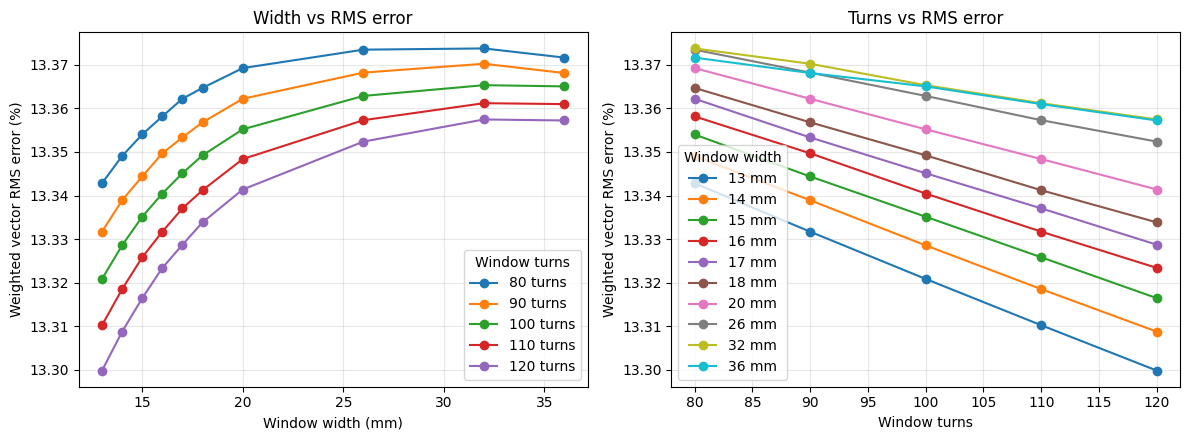

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Window width vs weighted vector error: one line per turn count.
turn_counts = sorted({d["turns"] for d in refined_designs})

for turns in turn_counts:
    group = sorted(
        (d for d in refined_designs if d["turns"] == turns),
        key=lambda d: d["window_width_m"],
    )
    axes[0].plot(
        [1000 * d["window_width_m"] for d in group],
        [d["quality"]["vector_rms_pct"] for d in group],
        marker="o",
        label=f"{turns} turns",
    )

axes[0].set_xlabel("Window width (mm)")
axes[0].set_ylabel("Weighted vector RMS error (%)")
axes[0].set_title("Width vs RMS error")
axes[0].legend(title="Window turns")

# Window turns vs weighted vector error: one line per width.
widths = sorted({d["window_width_m"] for d in refined_designs})

for width in widths:
    group = sorted(
        (d for d in refined_designs if d["window_width_m"] == width),
        key=lambda d: d["turns"],
    )
    axes[1].plot(
        [d["turns"] for d in group],
        [d["quality"]["vector_rms_pct"] for d in group],
        marker="o",
        label=f"{1000 * width:.0f} mm",
    )

axes[1].set_xlabel("Window turns")
axes[1].set_ylabel("Weighted vector RMS error (%)")
axes[1].set_title("Turns vs RMS error")
axes[1].legend(title="Window width")

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("Plot.png")
plt.show()